In [1]:
import pandas as pd

In [2]:
from enum import Enum
class point(Enum):
    CORE="CORE"
    BORDER="BORDER"
    NOISE="NOISE"

- Density at point `p`: number of a circle of radius `Eps`
- Dense Region: A circle of radius `Eps` that contains at least `MinPts` points

A point is a core point if it has more than a specified number of points `MinPts` within `Eps`
- These points belong in a dense region and are at the interator of a cluster
- Density-connected: if consecutive points is connected within radius of `Eps`

- core point: has at least neighbors points within `raidus` of `eps`
- border point: has less than `MinPts` but within core point
- noise point: not belong core point and border point

In [3]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.50, random_state=0)

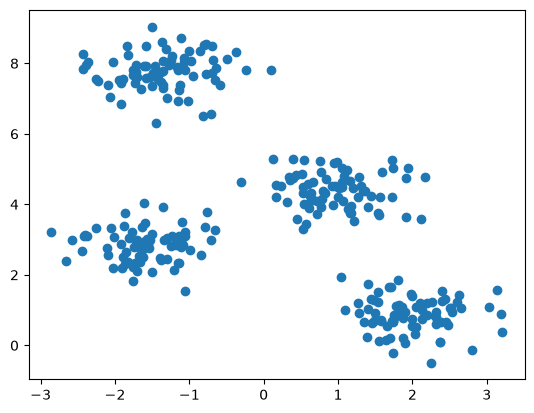

In [4]:
import matplotlib.pyplot as plt
plt.scatter(X[:,0], X[:, 1])
plt.show()

In [5]:
distance = []
for p in X:
    temp = []
    for p_ in X:
        eq = ((p_[0] - p[0]) ** 2 + (p_[1] - p_[1]) ** 2) ** 0.5
        temp.append(eq)
    distance.append(temp)

In [6]:
distance = pd.DataFrame(distance)

In [7]:
distance.shape

(300, 300)

In [8]:
import numpy as np 

In [9]:
data = np.array(distance)

In [10]:
distance

,0,1,2,3,4,5,6,7,8,9,...,290,291,292,293,294,295,296,297,298,299
0,0.000000,2.426016,0.085464,2.096815,0.362079,2.167301,2.801261,0.300890,1.418745,1.840551,...,1.214865,0.815618,2.181441,2.627194,2.311033,0.947367,1.401238,0.511388,0.940069,2.787291
1,2.426016,0.000000,2.511480,0.329201,2.788095,4.593317,0.375245,2.726906,1.007272,0.585465,...,3.640882,3.241634,0.244575,0.201178,0.114983,3.373384,3.827254,1.914628,1.485947,0.361274
2,0.085464,2.511480,0.000000,2.182279,0.276615,2.081837,2.886725,0.215426,1.504209,1.926015,...,1.129402,0.730154,2.266905,2.712658,2.396497,0.861904,1.315774,0.596852,1.025533,2.872754
3,2.096815,0.329201,2.182279,0.000000,2.458894,4.264115,0.704447,2.397705,0.678070,0.256264,...,3.311680,2.912433,0.084626,0.530379,0.214218,3.044182,3.498052,1.585426,1.156746,0.690476
4,0.362079,2.788095,0.276615,2.458894,0.000000,1.805222,3.163340,0.061189,1.780824,2.202630,...,0.852787,0.453539,2.543520,2.989273,2.673112,0.585289,1.039159,0.873467,1.302148,3.149369
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,0.947367,3.373384,0.861904,3.044182,0.585289,1.219933,3.748629,0.646477,2.366112,2.787918,...,0.267498,0.131750,3.128808,3.574561,3.258400,0.000000,0.453870,1.458756,1.887436,3.734658
296,1.401238,3.827254,1.315774,3.498052,1.039159,0.766063,4.202499,1.100347,2.819982,3.241788,...,0.186372,0.585620,3.582679,4.028431,3.712271,0.453870,0.000000,1.912626,2.341307,4.188528
297,0.511388,1.914628,0.596852,1.585426,0.873467,2.678689,2.289873,0.812279,0.907356,1.329162,...,1.726254,1.327006,1.670053,2.115805,1.799645,1.458756,1.912626,0.000000,0.428681,2.275902
298,0.940069,1.485947,1.025533,1.156746,1.302148,3.107370,1.861192,1.240959,0.478676,0.900482,...,2.154934,1.755687,1.241372,1.687125,1.370964,1.887436,2.341307,0.428681,0.000000,1.847222


In [11]:
data.shape

(300, 300)

In [12]:
EPS = 2.0
MinPts = 10

In [13]:
import numpy as np
import pandas as pd

def dbscan_manual(df, eps, min_samples):
    dist = df.values  # ma trận khoảng cách NxN
    n = dist.shape[0]

    # Bước 1: Tìm neighbors trong bán kính eps cho mỗi điểm
    count_matrix = []
    for row in dist:
        pts = [en for en in row if en <= eps]
        count_matrix.append(len(pts) - 1)

    point_type = []
    for pts in count_matrix: 
        is_core = "NOT"
        if pts >= min_samples:
            is_core = "core"
        point_type.append(is_core)

    core_indices = [i for i, t in enumerate(point_type) if t == "core"]

    for idx in range(len(point_type)):
        if point_type[idx] != "core":
            
            if any(dist[idx][j] <= eps for j in core_indices):
                point_type[idx] = "border"
            else:
                point_type[idx] = "noise"
                
    return point_type
            
result = dbscan_manual(distance, eps=1.0, min_samples=40)

result

['core',
 'core',
 'core',
 'core',
 'core',
 'border',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'border',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core',
 'core

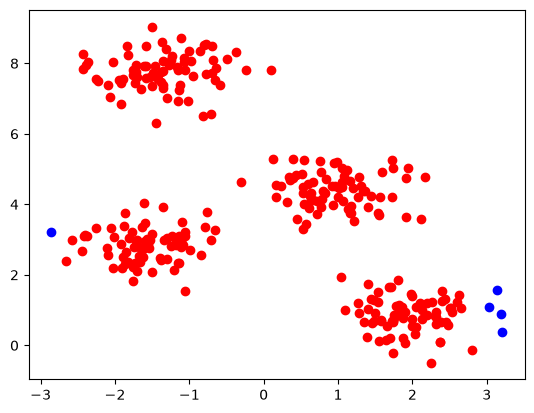

{'border', 'core'}

In [14]:
scheme = {"core": "red", "border": "blue", "noise": "grey"}

for idx in range(len(result)):
    plt.scatter(X[idx][0], X[idx][1], c=scheme[result[idx]])

plt.show()

set(result)   # thay cho result['type'].unique()

In [18]:
k = 4
rng = np.random.default_rng()
numbers = rng.integers(low = 0, high  = 299, size = 4)

random_pts = np.array([X[n] for n in numbers])
    
visited = np.full(shape = len(X), fill_value=False)

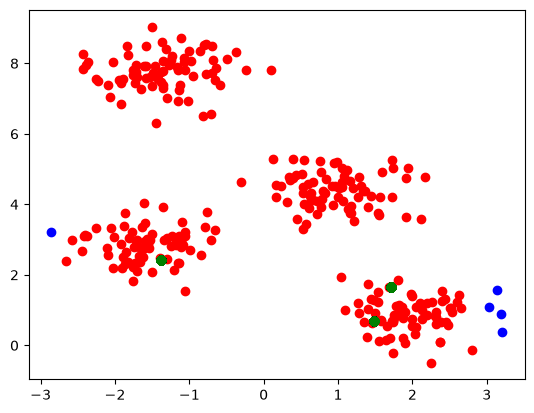

{'border', 'core'}

In [21]:
scheme = {"core": "red", "border": "blue", "noise": "grey"}

for idx in range(len(result)):
    plt.scatter(X[idx][0], X[idx][1], c=scheme[result[idx]])
    plt.scatter(random_pts[:, 0], random_pts[:, 1], c="green")

plt.show()

set(result)   # thay cho result['type'].unique()

In [22]:
def dbscan_cluster(dist, point_type, eps):
    n = 3
    cluster_id = np.full(n, -1)  
    visited = np.full(n, False)
    current_cluster = 0

    for idx in range(n):
        if visited[idx] or point_type[idx] != "core":
            continue

        
        stack = [idx]
        while stack:
            point = stack.pop()
            if visited[point]:
                continue
            visited[point] = True
            cluster_id[point] = current_cluster

            if point_type[point] == "core":
                neighbors = np.where(dist[point] <= eps)[0]
                for nb in neighbors:
                    if not visited[nb]:
                        stack.append(nb)

        current_cluster += 1

    return cluster_id

In [24]:
cluster_id = dbscan_cluster(distance.values, result, eps=1.0)
print(cluster_id)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0]


In [25]:
!pwd

/mnt/datassd/CodeHub/Science/WILD/DataMining/5
